# GAN Model 2: WGAN-GP (Wasserstein GAN with Gradient Penalty)

## Purpose
WGAN-GP offers several advantages over vanilla GAN:
- **More stable training** through Wasserstein distance
- **Better gradient flow** with gradient penalty instead of weight clipping
- **No mode collapse** - critic provides meaningful gradients throughout training

## Key Differences from Pix2Pix
- **Loss**: Wasserstein loss (no log) instead of BCE
- **Critic** (not discriminator): Outputs scalar (no sigmoid), trained more frequently
- **No BatchNorm in Critic**: Use LayerNorm or no normalization
- **Gradient Penalty**: Enforces 1-Lipschitz constraint

## Architecture
- **Generator**: Same U-Net as Pix2Pix
- **Critic**: Modified PatchGAN without BatchNorm, no sigmoid

## 1. Setup and Imports

In [1]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Run shared config notebook
%run "/content/drive/MyDrive/Paper1_ECG_Reconstruction/notebooks/00_SHARED_CONFIG.ipynb"

# Verify DEVICE was imported correctly (fallback if %run has scoping issues)
try:
    print(f"DEVICE successfully imported: {DEVICE}")
except NameError:
    import torch
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"DEVICE defined locally: {DEVICE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PyTorch: 2.9.0+cu126
CUDA: True
GPU: NVIDIA A100-SXM4-40GB (42.5 GB)
Recommended batch size: 32
Dependencies installed.
Device: cuda
PAPER 1: ECG RECONSTRUCTION - CONFIGURATION

Data:
  Chunks: /content/drive/MyDrive/October Thesis Dataset/Refine-Chunked
  Signal: 64000 samples (8.0s)

Training:
  Batch size: 16
  Epochs: 100
  Learning rate: 5e-05

Output:
  Results: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results
  Checkpoints: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints
Preprocessing functions loaded.
  - ensure_positive_polarity()
  - normalize_signal()
  - preprocess_ecg_pcg()
Augmentation functions loaded.
Dataset class loaded.
Metrics functions loaded:
  - calc_psnr(), calc_snr(), calc_correlation(), calc_ssim()
  - calc_mae(), calc_rmse()
  - calc_r_peak_error(), calc_qrs_width_error()
  - calc_all_metrics()
  - convert_to_se

In [16]:
def calc_all_metrics(real_ecg, fake_ecg, include_expensive=True):
    """Calculate all metrics for signals."""
    if torch.is_tensor(real_ecg):
        real_ecg = real_ecg.cpu().numpy()
    if torch.is_tensor(fake_ecg):
        fake_ecg = fake_ecg.cpu().numpy()

    # Handle single 1D sample [T]
    if real_ecg.ndim == 1:
        result = {
            'psnr': calc_psnr(real_ecg, fake_ecg),
            'snr': calc_snr(real_ecg, fake_ecg),
            'correlation': calc_correlation(real_ecg, fake_ecg),
            'ssim': calc_ssim(real_ecg, fake_ecg),
            'mae': calc_mae(real_ecg, fake_ecg),
            'rmse': calc_rmse(real_ecg, fake_ecg),
            'out_min': float(fake_ecg.min()),
            'out_max': float(fake_ecg.max()),
        }
        if include_expensive:
            result['r_peak_error'] = calc_r_peak_error(real_ecg, fake_ecg)
            result['qrs_width_error'] = calc_qrs_width_error(real_ecg, fake_ecg)
        return result

    # Handle [B, 1, T] -> [B, T]
    if real_ecg.ndim == 3:
        real_ecg = real_ecg.squeeze(1)
        fake_ecg = fake_ecg.squeeze(1)

    # Handle single sample with batch dim [1, T]
    if real_ecg.ndim == 2 and real_ecg.shape[0] == 1:
        real_ecg = real_ecg[0]
        fake_ecg = fake_ecg[0]
        result = {
            'psnr': calc_psnr(real_ecg, fake_ecg),
            'snr': calc_snr(real_ecg, fake_ecg),
            'correlation': calc_correlation(real_ecg, fake_ecg),
            'ssim': calc_ssim(real_ecg, fake_ecg),
            'mae': calc_mae(real_ecg, fake_ecg),
            'rmse': calc_rmse(real_ecg, fake_ecg),
            'out_min': float(fake_ecg.min()),
            'out_max': float(fake_ecg.max()),
        }
        if include_expensive:
            result['r_peak_error'] = calc_r_peak_error(real_ecg, fake_ecg)
            result['qrs_width_error'] = calc_qrs_width_error(real_ecg, fake_ecg)
        return result

    # Batch processing [B, T]
    batch_size = real_ecg.shape[0]
    metrics = {'psnr': [], 'snr': [], 'correlation': [], 'ssim': [], 'mae': [], 'rmse': []}
    if include_expensive:
        metrics['r_peak_error'] = []
        metrics['qrs_width_error'] = []

    for i in range(batch_size):
        real, fake = real_ecg[i], fake_ecg[i]
        metrics['psnr'].append(calc_psnr(real, fake))
        metrics['snr'].append(calc_snr(real, fake))
        metrics['correlation'].append(calc_correlation(real, fake))
        metrics['ssim'].append(calc_ssim(real, fake))
        metrics['mae'].append(calc_mae(real, fake))
        metrics['rmse'].append(calc_rmse(real, fake))
        if include_expensive:
            r_err = calc_r_peak_error(real, fake)
            qrs_err = calc_qrs_width_error(real, fake)
            if r_err is not None and not np.isnan(r_err):
                metrics['r_peak_error'].append(r_err)
            if qrs_err is not None and not np.isnan(qrs_err):
                metrics['qrs_width_error'].append(qrs_err)

    result = {k: float(np.mean(v)) if v else 0.0 for k, v in metrics.items()}
    result['out_min'] = float(fake_ecg.min())
    result['out_max'] = float(fake_ecg.max())
    return result

print("calc_all_metrics function updated!")

calc_all_metrics function updated!


In [17]:
# Model-specific configuration
MODEL_CONFIG = {
    'model_name': 'WGAN_GP',
    'batch_size': 16,
    'lr_g': 1e-4,         # Generator learning rate
    'lr_c': 1e-4,         # Critic learning rate
    'epochs': 100,
    'patience': 20,
    'lambda_l1': 100,     # L1 loss weight
    'lambda_gp': 10,      # Gradient penalty weight
    'n_critic': 5,        # Critic updates per generator update
}

# Create directories
model_save_dir = os.path.join(CONFIG['checkpoints_dir'], MODEL_CONFIG['model_name'])
model_results_dir = os.path.join(CONFIG['results_dir'], MODEL_CONFIG['model_name'])
os.makedirs(model_save_dir, exist_ok=True)
os.makedirs(model_results_dir, exist_ok=True)

print(f"Model: {MODEL_CONFIG['model_name']}")
print(f"Checkpoints: {model_save_dir}")
print(f"Results: {model_results_dir}")

Model: WGAN_GP
Checkpoints: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/WGAN_GP
Results: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/WGAN_GP


## 2. WGAN-GP Architecture

In [18]:
class UNetBlock(nn.Module):
    """U-Net encoder block."""
    def __init__(self, in_channels, out_channels, normalize=True, dropout=0.0):
        super().__init__()
        layers = [nn.Conv1d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.BatchNorm1d(out_channels))
        layers.append(nn.LeakyReLU(0.2, inplace=True))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)


class UNetUpBlock(nn.Module):
    """U-Net decoder block with skip connection."""
    def __init__(self, in_channels, out_channels, dropout=0.0):
        super().__init__()
        layers = [
            nn.ConvTranspose1d(in_channels, out_channels, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm1d(out_channels),
            nn.ReLU(inplace=True)
        ]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        self.block = nn.Sequential(*layers)

    def forward(self, x, skip):
        x = self.block(x)
        if x.size(2) != skip.size(2):
            diff = skip.size(2) - x.size(2)
            x = F.pad(x, (diff // 2, diff - diff // 2))
        return torch.cat([x, skip], dim=1)


class UNetGenerator(nn.Module):
    """U-Net Generator (same as Pix2Pix)."""
    def __init__(self, in_channels=1, out_channels=1, features=64):
        super().__init__()

        # Encoder
        self.e1 = UNetBlock(in_channels, features, normalize=False)
        self.e2 = UNetBlock(features, features * 2)
        self.e3 = UNetBlock(features * 2, features * 4)
        self.e4 = UNetBlock(features * 4, features * 8)
        self.e5 = UNetBlock(features * 8, features * 8)
        self.e6 = UNetBlock(features * 8, features * 8)
        self.e7 = UNetBlock(features * 8, features * 8)
        self.e8 = UNetBlock(features * 8, features * 8, normalize=False)

        # Decoder
        self.d1 = UNetUpBlock(features * 8, features * 8, dropout=0.5)
        self.d2 = UNetUpBlock(features * 16, features * 8, dropout=0.5)
        self.d3 = UNetUpBlock(features * 16, features * 8, dropout=0.5)
        self.d4 = UNetUpBlock(features * 16, features * 8)
        self.d5 = UNetUpBlock(features * 16, features * 4)
        self.d6 = UNetUpBlock(features * 8, features * 2)
        self.d7 = UNetUpBlock(features * 4, features)

        # Final - NO TANH
        self.final = nn.ConvTranspose1d(features * 2, out_channels, kernel_size=4, stride=2, padding=1)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(e1)
        e3 = self.e3(e2)
        e4 = self.e4(e3)
        e5 = self.e5(e4)
        e6 = self.e6(e5)
        e7 = self.e7(e6)
        e8 = self.e8(e7)

        d1 = self.d1(e8, e7)
        d2 = self.d2(d1, e6)
        d3 = self.d3(d2, e5)
        d4 = self.d4(d3, e4)
        d5 = self.d5(d4, e3)
        d6 = self.d6(d5, e2)
        d7 = self.d7(d6, e1)

        output = self.final(d7)

        if output.size(2) != x.size(2):
            diff = x.size(2) - output.size(2)
            output = F.pad(output, (diff // 2, diff - diff // 2))

        return output

In [19]:
class WGANCritic(nn.Module):
    """
    WGAN Critic (not discriminator).

    Key differences from PatchGAN:
    - NO BatchNorm (uses LayerNorm or nothing)
    - NO sigmoid output (outputs raw scores)
    - Called "critic" not "discriminator"
    """
    def __init__(self, in_channels=2, features=64):
        super().__init__()

        self.model = nn.Sequential(
            # Layer 1
            nn.Conv1d(in_channels, features, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 2 - NO BATCHNORM for WGAN-GP
            nn.Conv1d(features, features * 2, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 3
            nn.Conv1d(features * 2, features * 4, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # Layer 4
            nn.Conv1d(features * 4, features * 8, kernel_size=4, stride=1, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            # Output - NO sigmoid (critic outputs unbounded scores)
            nn.Conv1d(features * 8, 1, kernel_size=4, stride=1, padding=1),
        )

    def forward(self, x, y):
        combined = torch.cat([x, y], dim=1)
        return self.model(combined)

In [20]:
def compute_gradient_penalty(critic, pcg, real_ecg, fake_ecg, device):
    """
    Compute gradient penalty for WGAN-GP.

    The gradient penalty enforces the 1-Lipschitz constraint by penalizing
    the norm of the gradient of the critic output w.r.t. interpolated samples.
    """
    batch_size = real_ecg.size(0)

    # Random interpolation coefficient
    alpha = torch.rand(batch_size, 1, 1).to(device)

    # Interpolate between real and fake
    interpolated = (alpha * real_ecg + (1 - alpha) * fake_ecg).requires_grad_(True)

    # Critic output for interpolated samples
    critic_interpolated = critic(pcg, interpolated)

    # Compute gradients
    gradients = torch.autograd.grad(
        outputs=critic_interpolated,
        inputs=interpolated,
        grad_outputs=torch.ones_like(critic_interpolated),
        create_graph=True,
        retain_graph=True,
    )[0]

    # Flatten gradients
    gradients = gradients.view(batch_size, -1)

    # Compute gradient penalty
    gradient_penalty = ((gradients.norm(2, dim=1) - 1) ** 2).mean()

    return gradient_penalty

In [21]:
# Initialize models
generator = UNetGenerator(in_channels=1, out_channels=1, features=64).to(DEVICE)
critic = WGANCritic(in_channels=2, features=64).to(DEVICE)

# Count parameters
g_params = sum(p.numel() for p in generator.parameters())
c_params = sum(p.numel() for p in critic.parameters())
print(f"Generator parameters: {g_params:,}")
print(f"Critic parameters: {c_params:,}")
print(f"Total parameters: {g_params + c_params:,}")

# Test forward pass
test_pcg = torch.randn(2, 1, CONFIG['signal_length']).to(DEVICE)
test_ecg = generator(test_pcg)
test_c = critic(test_pcg, test_ecg)
print(f"\nGenerator input: {test_pcg.shape}, output: {test_ecg.shape}")
print(f"Critic output: {test_c.shape}")

Generator parameters: 13,609,345
Critic parameters: 691,649
Total parameters: 14,300,994

Generator input: torch.Size([2, 1, 64000]), output: torch.Size([2, 1, 64000])
Critic output: torch.Size([2, 1, 7998])


## 3. Load Data

In [22]:
# Load datasets using shared utilities
train_loader, val_loader, test_loader, train_dataset = create_dataloaders(CONFIG)

# Quick verification
sample_batch = next(iter(train_loader))
print(f"\nBatch verification:")
print(f"  PCG shape: {sample_batch['pcg'].shape}")
print(f"  ECG shape: {sample_batch['ecg'].shape}")

Loading datasets...
TRAIN: 4059 chunks from 14 subjects
  Scenarios: Rest=1134, Exercise=2925, Other=0
VAL: 681 chunks from 3 subjects
  Scenarios: Rest=231, Exercise=450, Other=0
TEST: 453 chunks from 3 subjects
  Scenarios: Rest=3, Exercise=450, Other=0

Dataloaders created:
  Train: 253 batches
  Val: 43 batches
  Test: 29 batches

Batch verification:
  PCG shape: torch.Size([16, 1, 64000])
  ECG shape: torch.Size([16, 1, 64000])


In [23]:
# Dataloaders already created
print(f"Train: {len(train_loader)} batches, Val: {len(val_loader)} batches, Test: {len(test_loader)} batches")

Train: 253 batches, Val: 43 batches, Test: 29 batches


## 4. Training Setup

In [24]:
# Loss function for reconstruction
criterion_l1 = nn.L1Loss()

# Optimizers (Adam for both, but can use RMSprop for WGAN)
optimizer_g = torch.optim.Adam(generator.parameters(), lr=MODEL_CONFIG['lr_g'], betas=(0.0, 0.9))
optimizer_c = torch.optim.Adam(critic.parameters(), lr=MODEL_CONFIG['lr_c'], betas=(0.0, 0.9))

# Learning rate schedulers - CosineAnnealingLR
scheduler_g = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_g, T_max=MODEL_CONFIG['epochs'], eta_min=1e-6)
scheduler_c = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_c, T_max=MODEL_CONFIG['epochs'], eta_min=1e-6)

# Early stopping
early_stopping = EarlyStopping(patience=MODEL_CONFIG['patience'], min_delta=0.001)

## 5. Training Loop

In [25]:
def train_epoch_wgan(generator, critic, train_loader, criterion_l1,
                     optimizer_g, optimizer_c, device, lambda_l1, lambda_gp, n_critic):
    generator.train()
    critic.train()

    total_g_loss = 0.0
    total_c_loss = 0.0
    total_gp = 0.0
    n_batches = 0

    for batch_idx, batch in enumerate(train_loader):
        pcg = batch['pcg'].to(device)
        ecg_real = batch['ecg'].to(device)
        batch_size = pcg.size(0)

        # ---------------------
        # Train Critic (more frequently than generator)
        # ---------------------
        for _ in range(n_critic):
            optimizer_c.zero_grad()

            # Generate fake ECG
            ecg_fake = generator(pcg).detach()

            # Critic scores (higher for real, lower for fake)
            c_real = critic(pcg, ecg_real).mean()
            c_fake = critic(pcg, ecg_fake).mean()

            # Wasserstein loss: maximize E[C(real)] - E[C(fake)]
            # Equivalent to minimizing -E[C(real)] + E[C(fake)]
            wasserstein_loss = c_fake - c_real

            # Gradient penalty
            gp = compute_gradient_penalty(critic, pcg, ecg_real, ecg_fake, device)

            # Total critic loss
            loss_c = wasserstein_loss + lambda_gp * gp
            loss_c.backward()
            torch.nn.utils.clip_grad_norm_(critic.parameters(), CONFIG['grad_clip'])
            optimizer_c.step()

        total_c_loss += wasserstein_loss.item()
        total_gp += gp.item()

        # -----------------
        # Train Generator
        # -----------------
        optimizer_g.zero_grad()

        # Generate fake ECG
        ecg_fake = generator(pcg)

        # Generator wants critic to score fake as high as possible
        c_fake = critic(pcg, ecg_fake).mean()
        loss_g_adv = -c_fake  # Minimize -E[C(fake)]

        # L1 reconstruction loss
        loss_g_l1 = criterion_l1(ecg_fake, ecg_real)

        # Total generator loss
        loss_g = loss_g_adv + lambda_l1 * loss_g_l1
        loss_g.backward()
        torch.nn.utils.clip_grad_norm_(generator.parameters(), CONFIG['grad_clip'])
        optimizer_g.step()

        total_g_loss += loss_g.item()
        n_batches += 1

    return total_g_loss / n_batches, total_c_loss / n_batches, total_gp / n_batches


def validate_epoch(generator, val_loader, criterion_l1, device):
    generator.eval()
    total_loss = 0.0
    all_metrics = []

    with torch.no_grad():
        for batch in val_loader:
            pcg = batch['pcg'].to(device)
            ecg_real = batch['ecg'].to(device)
            ecg_fake = generator(pcg)
            loss = criterion_l1(ecg_fake, ecg_real)
            total_loss += loss.item()

            for i in range(ecg_real.size(0)):
                all_metrics.append(calc_all_metrics(
                    ecg_fake[i, 0].cpu().numpy(),
                    ecg_real[i, 0].cpu().numpy()
                ))

    avg_metrics = {}
    for key in all_metrics[0].keys():
        values = [m[key] for m in all_metrics if m[key] is not None]
        avg_metrics[key] = np.mean(values) if values else None

    return total_loss / len(val_loader), avg_metrics

In [26]:
# Training history
history = {
    'g_loss': [], 'c_loss': [], 'gp': [], 'val_loss': [],
    'val_psnr': [], 'val_ssim': [], 'val_correlation': [],
    'lr_g': [], 'lr_c': []
}
best_val_loss = float('inf')
best_epoch = 0

print(f"Starting training: {MODEL_CONFIG['model_name']}")
print(f"Epochs: {MODEL_CONFIG['epochs']}, Batch: {MODEL_CONFIG['batch_size']}, Device: {DEVICE}")
print(f"Lambda L1: {MODEL_CONFIG['lambda_l1']}, Lambda GP: {MODEL_CONFIG['lambda_gp']}, n_critic: {MODEL_CONFIG['n_critic']}")
print("=" * 70)

Starting training: WGAN_GP
Epochs: 100, Batch: 16, Device: cuda
Lambda L1: 100, Lambda GP: 10, n_critic: 5


In [27]:
# Main training loop
for epoch in range(MODEL_CONFIG['epochs']):
    # Set epoch for progressive augmentation
    train_dataset.set_epoch(epoch)

    # Train
    g_loss, c_loss, gp = train_epoch_wgan(
        generator, critic, train_loader,
        criterion_l1, optimizer_g, optimizer_c, DEVICE,
        MODEL_CONFIG['lambda_l1'], MODEL_CONFIG['lambda_gp'], MODEL_CONFIG['n_critic']
    )

    # Validate
    val_loss, val_metrics = validate_epoch(generator, val_loader, criterion_l1, DEVICE)

    # Update schedulers
    scheduler_g.step()
    scheduler_c.step()

    # Record history
    history['g_loss'].append(g_loss)
    history['c_loss'].append(c_loss)
    history['gp'].append(gp)
    history['val_loss'].append(val_loss)
    history['val_psnr'].append(val_metrics['psnr'])
    history['val_ssim'].append(val_metrics['ssim'])
    history['val_correlation'].append(val_metrics['correlation'])
    history['lr_g'].append(optimizer_g.param_groups[0]['lr'])
    history['lr_c'].append(optimizer_c.param_groups[0]['lr'])

    print(f"Epoch [{epoch+1}/{MODEL_CONFIG['epochs']}] "
          f"G: {g_loss:.4f} | C: {c_loss:.4f} | GP: {gp:.4f} | Val: {val_loss:.4f} | "
          f"PSNR: {val_metrics['psnr']:.2f} | SSIM: {val_metrics['ssim']:.4f}")

    # Save best model
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        save_checkpoint(generator, optimizer_g, epoch, val_loss, os.path.join(model_save_dir, 'best_model.pt'), MODEL_CONFIG['model_name'])
        print(f"  -> New best model saved!")

    # Early stopping
    if early_stopping(val_loss):
        print(f"\nEarly stopping at epoch {epoch+1}")
        break

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        save_checkpoint(generator, optimizer_g, epoch, val_loss, os.path.join(model_save_dir, f'checkpoint_epoch_{epoch+1}.pt'), MODEL_CONFIG['model_name'])

print(f"\nTraining completed! Best epoch: {best_epoch}, Best val loss: {best_val_loss:.4f}")

Epoch [1/100] G: 80.9286 | C: -0.0144 | GP: 0.0199 | Val: 0.6573 | PSNR: 8.57 | SSIM: 0.5858
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/WGAN_GP/best_model.pt
  -> New best model saved!
Epoch [2/100] G: 68.7499 | C: -0.0134 | GP: 0.0023 | Val: 0.6690 | PSNR: 5.33 | SSIM: 0.6377
Epoch [3/100] G: 67.1157 | C: -0.0132 | GP: 0.0018 | Val: 0.6744 | PSNR: 7.97 | SSIM: 0.6268
Epoch [4/100] G: 66.0733 | C: -0.0127 | GP: 0.0017 | Val: 0.6723 | PSNR: 8.10 | SSIM: 0.7505
Epoch [5/100] G: 64.9426 | C: -0.0121 | GP: 0.0014 | Val: 0.6485 | PSNR: 9.67 | SSIM: 0.7276
Checkpoint saved: /content/drive/MyDrive/Paper1_ECG_Reconstruction/checkpoints/WGAN_GP/best_model.pt
  -> New best model saved!
Epoch [6/100] G: 64.3068 | C: -0.0121 | GP: 0.0018 | Val: 0.6622 | PSNR: 10.85 | SSIM: 0.7927
Epoch [7/100] G: 63.4119 | C: -0.0116 | GP: 0.0013 | Val: 0.6655 | PSNR: 8.50 | SSIM: 0.7822
Epoch [8/100] G: 62.9406 | C: -0.0116 | GP: 0.0013 | Val: 0.6827 | PSNR: 13.33 | SSIM: 0.825

In [28]:
# Save training history
history_path = os.path.join(model_results_dir, 'training_history.json')
with open(history_path, 'w') as f:
    json.dump(convert_to_serializable(history), f, indent=2)
print(f"Training history saved to: {history_path}")

Training history saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/WGAN_GP/training_history.json


## 6. Plot Training Curves

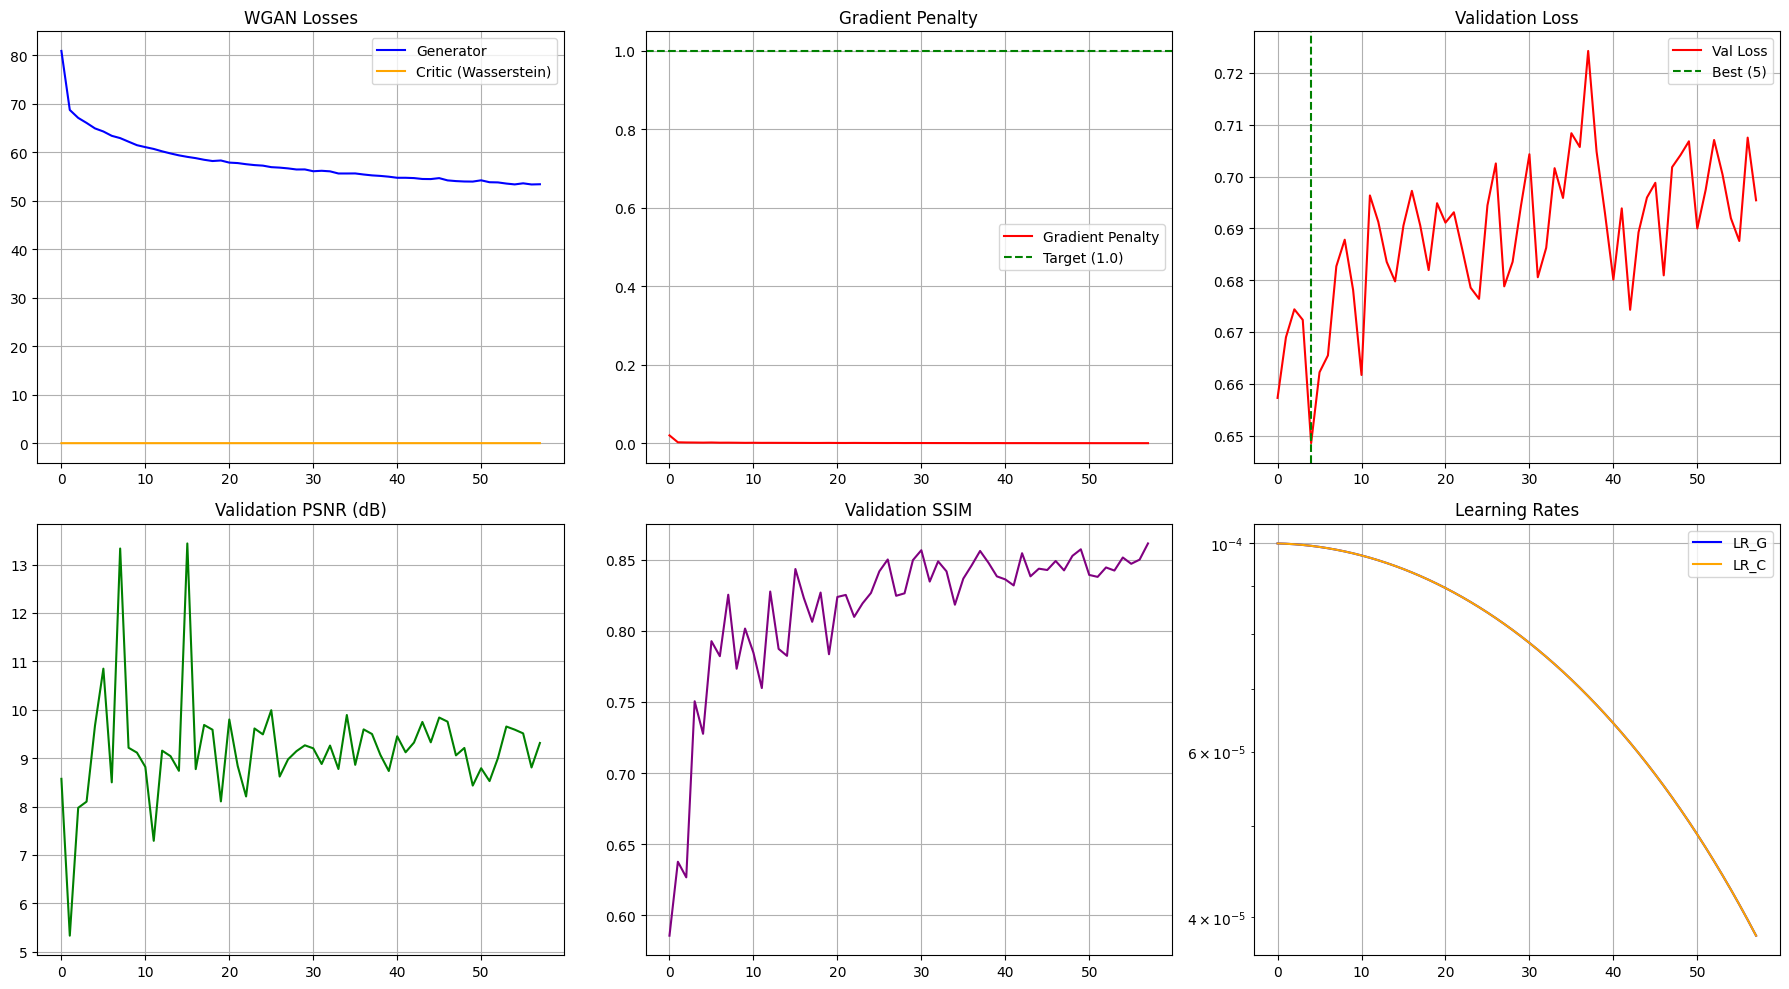

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# WGAN losses
axes[0, 0].plot(history['g_loss'], label='Generator', color='blue')
axes[0, 0].plot(history['c_loss'], label='Critic (Wasserstein)', color='orange')
axes[0, 0].set_title('WGAN Losses'); axes[0, 0].legend(); axes[0, 0].grid(True)

# Gradient penalty
axes[0, 1].plot(history['gp'], label='Gradient Penalty', color='red')
axes[0, 1].axhline(y=1.0, color='green', linestyle='--', label='Target (1.0)')
axes[0, 1].set_title('Gradient Penalty'); axes[0, 1].legend(); axes[0, 1].grid(True)

# Validation loss
axes[0, 2].plot(history['val_loss'], label='Val Loss', color='red')
axes[0, 2].axvline(x=best_epoch-1, color='green', linestyle='--', label=f'Best ({best_epoch})')
axes[0, 2].set_title('Validation Loss'); axes[0, 2].legend(); axes[0, 2].grid(True)

# PSNR
axes[1, 0].plot(history['val_psnr'], color='green')
axes[1, 0].set_title('Validation PSNR (dB)'); axes[1, 0].grid(True)

# SSIM
axes[1, 1].plot(history['val_ssim'], color='purple')
axes[1, 1].set_title('Validation SSIM'); axes[1, 1].grid(True)

# Learning rates
axes[1, 2].plot(history['lr_g'], label='LR_G', color='blue')
axes[1, 2].plot(history['lr_c'], label='LR_C', color='orange')
axes[1, 2].set_title('Learning Rates'); axes[1, 2].set_yscale('log'); axes[1, 2].legend(); axes[1, 2].grid(True)

plt.tight_layout()
plt.savefig(os.path.join(model_results_dir, 'training_curves.png'), dpi=150)
plt.show()

## 7. Test Evaluation

In [31]:
  # Load best model
  checkpoint = torch.load(os.path.join(model_save_dir, 'best_model.pt'), weights_only=False)
  generator.load_state_dict(checkpoint['model_state_dict'])
  print(f"Loaded best model from epoch {checkpoint['epoch'] + 1}")

Loaded best model from epoch 5


In [32]:
# Evaluate on test set
generator.eval()
test_metrics = []
test_predictions, test_targets, test_inputs = [], [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc='Evaluating'):
        pcg = batch['pcg'].to(DEVICE)
        ecg = batch['ecg'].to(DEVICE)
        ecg_pred = generator(pcg)

        test_predictions.append(ecg_pred.cpu().numpy())
        test_targets.append(ecg.cpu().numpy())
        test_inputs.append(pcg.cpu().numpy())

        for i in range(ecg.size(0)):
            test_metrics.append(calc_all_metrics(ecg_pred[i, 0].cpu().numpy(), ecg[i, 0].cpu().numpy()))

test_predictions = np.concatenate(test_predictions, axis=0)
test_targets = np.concatenate(test_targets, axis=0)
test_inputs = np.concatenate(test_inputs, axis=0)
print(f"Test samples: {len(test_metrics)}")

Evaluating:   0%|          | 0/29 [00:00<?, ?it/s]

Test samples: 453


In [33]:
# Calculate summary statistics
summary_stats = {}
for key in test_metrics[0].keys():
    values = [m[key] for m in test_metrics if m[key] is not None]
    if values:
        summary_stats[key] = {
            'mean': float(np.mean(values)), 'std': float(np.std(values)),
            'min': float(np.min(values)), 'max': float(np.max(values)), 'median': float(np.median(values))
        }

print("\n" + "=" * 60)
print(f"TEST RESULTS: {MODEL_CONFIG['model_name']}")
print("=" * 60)
print(f"{'Metric':<20} {'Mean':>10} {'Std':>10} {'Min':>10} {'Max':>10}")
print("-" * 60)
for key, stats in summary_stats.items():
    print(f"{key:<20} {stats['mean']:>10.4f} {stats['std']:>10.4f} {stats['min']:>10.4f} {stats['max']:>10.4f}")
print("=" * 60)


TEST RESULTS: WGAN_GP
Metric                     Mean        Std        Min        Max
------------------------------------------------------------
psnr                    11.7174     4.1179     3.0179    38.2308
snr                     -6.9157     4.0216   -13.0629     1.6989
correlation              0.3918     0.2835    -0.6072     0.8754
ssim                     0.6997     0.0913     0.4638     0.9375
mae                      0.6351     0.1297     0.3819     0.8808
rmse                     0.8861     0.1503     0.5515     1.3936
out_min                 -3.0115     0.5407    -4.8329    -1.7001
out_max                  4.5201     0.7241     2.5971     8.7300
r_peak_error             0.9052     0.2711     0.3788     2.6111
qrs_width_error          7.8777     1.6776     3.5183    12.4156


In [34]:
# Save test results
test_results = {
    'model_name': MODEL_CONFIG['model_name'],
    'model_config': MODEL_CONFIG,
    'test_samples': len(test_metrics),
    'summary_statistics': summary_stats,
    'best_epoch': best_epoch,
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

results_path = os.path.join(model_results_dir, 'test_results.json')
with open(results_path, 'w') as f:
    json.dump(convert_to_serializable(test_results), f, indent=2)
print(f"Results saved to: {model_results_dir}")

Results saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/WGAN_GP


## 8. Visualize Reconstructions

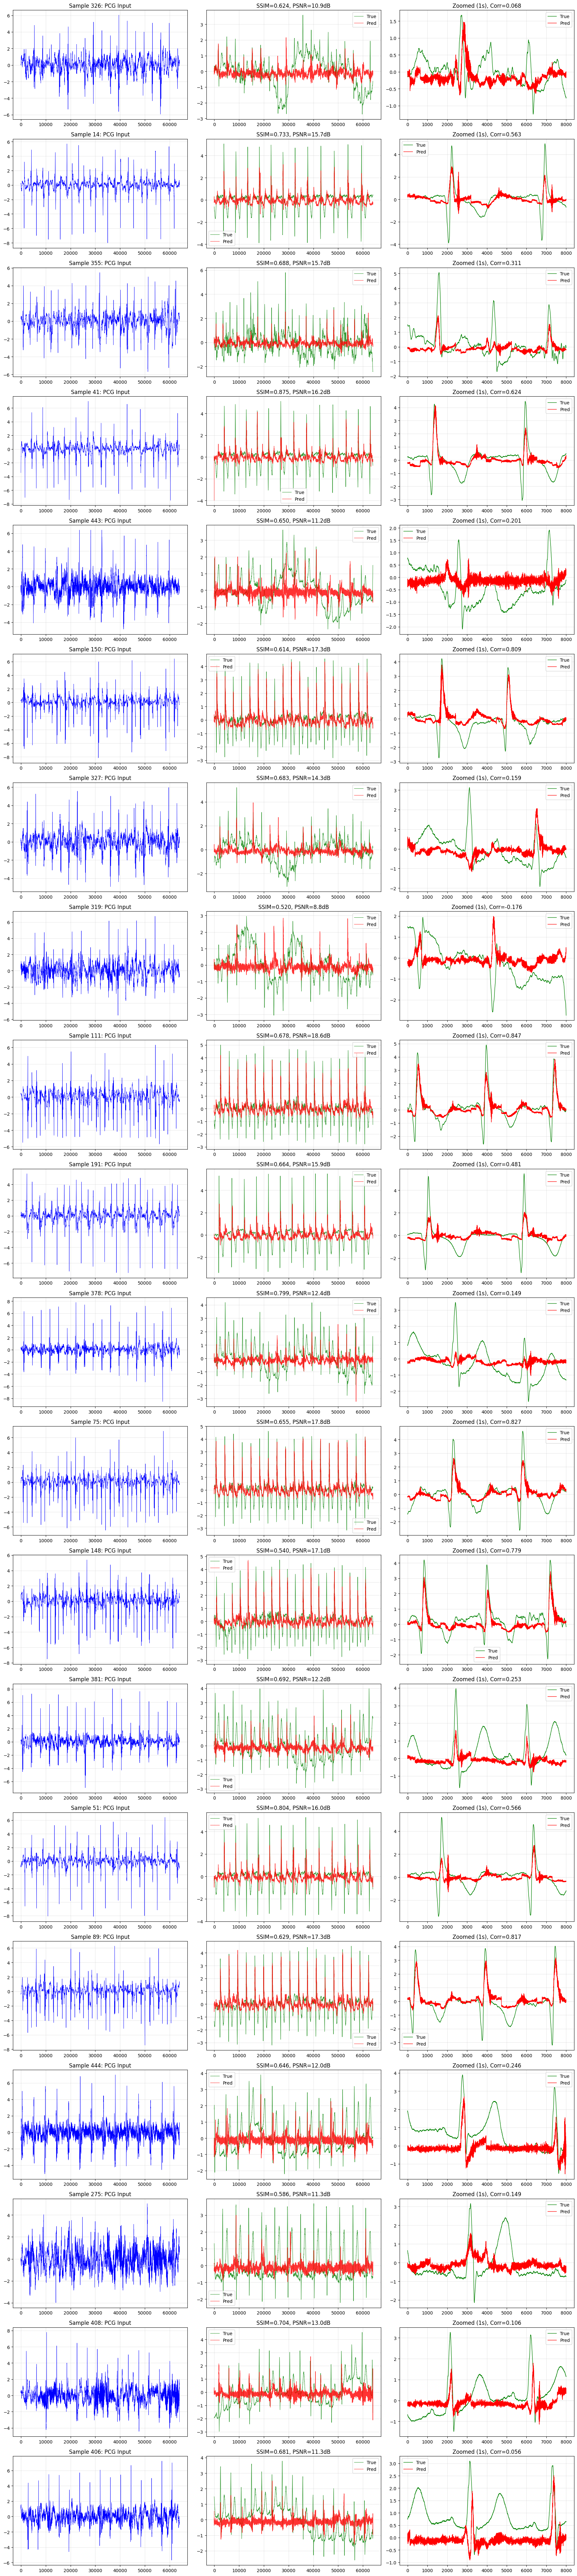

In [36]:
# Visualize sample reconstructions
n_samples = 20
sample_indices = np.random.choice(len(test_predictions), n_samples, replace=False)

fig, axes = plt.subplots(n_samples, 3, figsize=(18, 4*n_samples))

for i, idx in enumerate(sample_indices):
    pcg = test_inputs[idx, 0]
    ecg_true = test_targets[idx, 0]
    ecg_pred = test_predictions[idx, 0]

    # Calculate metrics on-the-fly for this sample
    sample_ssim = calc_ssim(ecg_true, ecg_pred)
    sample_psnr = calc_psnr(ecg_true, ecg_pred)
    sample_corr = calc_correlation(ecg_true, ecg_pred)

    axes[i, 0].plot(pcg, color='blue', linewidth=0.5)
    axes[i, 0].set_title(f'Sample {idx}: PCG Input'); axes[i, 0].grid(True, alpha=0.3)

    axes[i, 1].plot(ecg_true, color='green', linewidth=0.8, label='True', alpha=0.8)
    axes[i, 1].plot(ecg_pred, color='red', linewidth=0.8, label='Pred', alpha=0.8)
    axes[i, 1].set_title(f'SSIM={sample_ssim:.3f}, PSNR={sample_psnr:.1f}dB')
    axes[i, 1].legend(); axes[i, 1].grid(True, alpha=0.3)

    zoom_start = len(ecg_true) // 4
    zoom_end = zoom_start + CONFIG['sample_rate']
    axes[i, 2].plot(ecg_true[zoom_start:zoom_end], color='green', linewidth=1.0, label='True')
    axes[i, 2].plot(ecg_pred[zoom_start:zoom_end], color='red', linewidth=1.0, label='Pred')
    axes[i, 2].set_title(f'Zoomed (1s), Corr={sample_corr:.3f}')
    axes[i, 2].legend(); axes[i, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(model_results_dir, 'sample_reconstructions.png'), dpi=300)
plt.show()

## 9. Summary

In [37]:
print("\n" + "=" * 60)
print("FINAL SUMMARY FOR MODEL COMPARISON")
print("=" * 60)
print(f"Model: {MODEL_CONFIG['model_name']}")
print(f"Architecture: WGAN-GP (U-Net Generator + Critic without BatchNorm)")
print(f"Loss: Wasserstein + Gradient Penalty (lambda={MODEL_CONFIG['lambda_gp']}) + L1 (lambda={MODEL_CONFIG['lambda_l1']})")
print("-" * 60)
print("KEY METRICS:")
print(f"  SSIM:        {summary_stats['ssim']['mean']:.4f} +/- {summary_stats['ssim']['std']:.4f}")
print(f"  PSNR:        {summary_stats['psnr']['mean']:.2f} +/- {summary_stats['psnr']['std']:.2f} dB")
print(f"  Correlation: {summary_stats['correlation']['mean']:.4f} +/- {summary_stats['correlation']['std']:.4f}")
print("=" * 60)
print("\nWGAN-GP advantages:")
print("  - More stable training (no mode collapse)")
print("  - Better gradient flow throughout training")
print("  - Critic provides meaningful gradients even when near-optimal")
print(f"\nNotebook completed! Results saved to: {model_results_dir}")


FINAL SUMMARY FOR MODEL COMPARISON
Model: WGAN_GP
Architecture: WGAN-GP (U-Net Generator + Critic without BatchNorm)
Loss: Wasserstein + Gradient Penalty (lambda=10) + L1 (lambda=100)
------------------------------------------------------------
KEY METRICS:
  SSIM:        0.6997 +/- 0.0913
  PSNR:        11.72 +/- 4.12 dB
  Correlation: 0.3918 +/- 0.2835

WGAN-GP advantages:
  - More stable training (no mode collapse)
  - Better gradient flow throughout training
  - Critic provides meaningful gradients even when near-optimal

Notebook completed! Results saved to: /content/drive/MyDrive/Paper1_ECG_Reconstruction/results/WGAN_GP
